# Модели, обученные под эпилепсию, без дообучения: DeepEpilepsy, SpikeNet1, SenuaLab — EpiEEG-60 и Турция (Г1)

| Поле | Значение |
|------|----------|
| **Автор** | Захар Санников (zs) |
| **Дата** | 2026-10-29 |
| **Гипотеза** | Г1 (ЭЭГ) |
| **Ядро Kaggle** | `zakharsann/h1-epilepsy-models` (GPU T4, 50 мин, только вывод; первые две попытки упали на ошибках кода и вывода не дали). Дальше — локальные ячейки по небольшим csv |
| **Результаты** | `h1_eeg/results/epimodels_*.csv`, `h1_eeg/results/figures/epimodels_roc.png` |

## Какие модели доступны (проверено 2026-10-29)

| Модель | Веса | Лицензия | Статус |
|---|---|---|---|
| DeepEpilepsy (HF `emilelemoine/DeepEpilepsy_v1`) | на HF, без заявки; рабочие: Large 30 с и ещё 3 файла | MIT | **прогнана** (Large 50, 30 с) |
| SpikeNet1.o (GitHub `bdsp-core/SpikeNet1`) | в репозитории (`spikenet1.o_weights.h5`, 1,3 МБ), Keras 2.2.2 | CC BY-NC 4.0, коммерция запрещена | **прогнана**, перенесена в PyTorch (совпадение с выходом авторов на их примере: разность 0,0000) |
| SpikeNet2 (GitHub `bdsp-core/SpikeNet2`, NEJM AI 2025) | `new_weights.ckpt` лежит в `s3://bdsp-opendata-restricted/…` — **доступ по заявке** (bdsp.io, credentialed) | код под нестандартной лицензией (NOASSERTION), данные закрытые | **не взята**: нужна заявка |
| SenuaLab EEG-DINO Medium, IEDNet-Lite (HF `SenuaLab/EEG-IED-Detection`, обучены на vEpiSet) | на HF, без заявки | код MIT; контрольные точки CC BY 4.0 (указывать SenuaLab и vEpiSet); у EEG-DINO оговорка про ограничения данных предобучения | **прогнаны** на EpiEEG-60; на Турции использованы прежние оценки (`ied_senualab_turkish_per_person.csv`, тот же код и окна) |
| ProtoEEGNet, Cyclops, EpiNT, модели на NMT-Events | в поиске открытых весов **не найдено / не проверено** (по сниппетам поисковика); не включены |  |  |

## Подготовка — как у авторов
- **DeepEpilepsy** (код и статья Lemoine 2025): порядок каналов `settings.ELECTRODES`, референт «среднее ушных» (A1+A2)/2, 200 Гц, **программных фильтров нет** (фильтры только в аугментации), окна 30 с, перекрытие 95 % (шаг 1,5 с), `standard_scale` по каналам, оценка записи — медиана окон. Дополнительно два варианта: средний референт, ФВЧ 0,5 Гц. Предыдущий прогон на Турции (фильтр 0,5–70 Гц, 30 с без перекрытия) здесь повторён по подготовке авторов; результат тот же.
- **SpikeNet1**: код `run_spikenet.py` — 19 каналов, средний референт + 18 биполярных, 128 Гц, ФВЧ 0,5 Гц, режекция (50 Гц вместо 60), окна 1 с; шаг 4 отсчёта вместо 1 (ради скорости).
- **SenuaLab**: код авторов `preprocess_array`, окна 4 с, шаг 2 с, порог авторов.

## Выводы
1. **DeepEpilepsy без дообучения не работает ни на одном из наборов, и результат хуже случайного:** EpiEEG-60 ROC AUC **0,42 (0,28–0,57)**, Турция **0,38 (0,28–0,48)**; при среднем референте 0,36 / 0,56, с ФВЧ — 0,41 / 0,38. Разность с REVE v4 значима и в худшую сторону (−0,34 и −0,55). На EpiEEG-60 модель называет «эпилепсия» почти всех (медиана вероятности 0,99 у обеих групп), на Турции — почти никого (≈0,01). Это не опровергает авторский 0,76 в их клинике: данные нашего вида модель не переносит. Ушной референт в EpiEEG-60 шумный (A1: СКО 52 мкВ против A2: 17 мкВ после ФВЧ), так что «правильность» референта для неё под вопросом, но вариант со средним референтом тоже не помогает.
2. **Детекторы разрядов работают как детекторы, но как признак «эпилепсия» слабее REVE v4.** На размеченных врачом отрезках EpiEEG-60 (115 пометок) против случайных отрезков тех же записей: SpikeNet1 ROC AUC **0,92**, EEG-DINO 0,84, IEDNet-Lite 0,81 — перенос на этот прибор технически рабочий. Но на уровне человека:
   - EpiEEG-60: SpikeNet1 (частота разрядов) 0,685 (0,55–0,81), IEDNet-Lite 0,72 (0,59–0,84), EEG-DINO 0,63–0,67; от REVE v4 (0,761) по паре — не отличаются (все ДИ разности накрывают 0).
   - Турция: SpikeNet1 0,65 (0,55–0,75), SenuaLab 0,43–0,55; все хуже REVE v4 (0,923) значимо.
   - Максимум вероятности — плохой признак (у SpikeNet1 0,43 и 0,59): почти у каждого человека находится окно с p ≈ 1.
3. **Ансамбль с REVE v4 (среднее рангов) не улучшает.** EpiEEG-60: REVE+SpikeNet1 0,758 (разность −0,003, −0,09…+0,08), REVE+EEG-DINO 0,736, REVE+DeepEpilepsy 0,654. Турция: REVE+SpikeNet1 0,856 (−0,067, значимо хуже), REVE+EEG-DINO 0,806, REVE+DeepEpilepsy 0,703. Пороговые метрики (Юден, k = 20, 500 повторов) ниже или равны REVE v4: EpiEEG-60 balanced accuracy 0,65 против 0,69, Турция 0,74 против 0,81.
4. **Больные с размеченными разрядами и без** (каждая группа против всех здоровых EpiEEG-60). С пометками (n = 24): REVE v4 0,807; SpikeNet1 0,703; IEDNet-Lite 0,724; EEG-DINO 0,693; ансамбль REVE+SpikeNet1 0,791. Без пометок (n = 7): REVE v4 0,603 (0,32–0,87); IEDNet-Lite 0,714, SpikeNet1 0,625 — выше точечно, но разности с REVE (+0,11 и +0,02) с ДИ −0,16…+0,36 и −0,31…+0,35: **при 7 больных ничего утверждать нельзя**. Оговорка: «без пометок» — это отсутствие пометки в служебном файле, не доказанное отсутствие разрядов.
5. **Вывод для проекта:** готовые модели «под эпилепсию» в чистом виде (DeepEpilepsy) на других клиниках не переносятся; детекторы разрядов переносятся технически, но дают признак слабее, чем REVE v4, обученная на NMT, и ансамбль выигрыша не даёт. Частота разрядов как второй признак остаётся осмысленной идеей для интерпретации (подсветка окон врачу), но не для повышения AUC без дообучения.

**Ограничения.** n = 63 и 121 человек, ДИ широкие. Метка EpiEEG-60 в значительной мере определена теми же разрядами, которые ловят детекторы («круговая» метка). Турция: SenuaLab-оценки взяты из прежнего прогона (50 Гц-режекция там не применялась — по коду авторов, фильтр 1–45 Гц). Вариант SpikeNet1 с шагом 31 мс вместо 2 мс может слегка менять частоту разрядов. Порог SpikeNet1 0,5 выбран заранее, не подбирался. Пороги «Юден на k = 20» — метрики на оставшихся 43 / 101 людях. Перекрытие окон DeepEpilepsy 95 % делает окна сильно зависимыми, медиана устойчива к этому. Лицензии: SpikeNet1 — только некоммерческое использование.


# Модели, обученные под эпилепсию, без дообучения: DeepEpilepsy, SpikeNet1, SenuaLab (Г1)
| Поле | Значение |
|------|----------|
| **Автор** | Захар Санников (zs) |
| **Дата** | 2026-10-29 |
| **Ядро** | `zakharsann/h1-epilepsy-models` (GPU T4), только вывод |
| **Данные** | EpiEEG-60 (Mendeley 10.17632/gg88rc79vv v4, CC BY 4.0) — скачивается внутри ядра заново, т. к. нужны исходные 500 Гц и ушные электроды A1/A2; Турция (`buraktaci/turkish-epilepsy`) |
| **Модели** | DeepEpilepsy (HF `emilelemoine/DeepEpilepsy_v1`, MIT); SpikeNet1.o (GitHub `bdsp-core/SpikeNet1`, веса в репозитории, CC BY-NC 4.0); SenuaLab EEG-IED-Detection (HF `SenuaLab/EEG-IED-Detection`, обучен на vEpiSet) |

Подготовка — как требует каждая модель:
- **DeepEpilepsy** (статья Lemoine 2025 и код авторов): 19 каналов в порядке `settings.ELECTRODES`, референт «среднее ушных» (A1+A2)/2, 200 Гц, программных фильтров нет (только в аугментации), окна 30 с с перекрытием 95 % (шаг 1,5 с), нормировка каждого канала в окне (`standard_scale`), оценка записи — медиана вероятностей окон. Варианты для проверки: средний референт; уши + ФВЧ 0,5 Гц.
- **SpikeNet1.o** (`run_spikenet.py`): 19 монополярных каналов → 128 Гц → 19 каналов в среднем референте + 18 продольных биполярных (37) → ФВЧ 0,5 Гц (FIR, MNE) → режекция сети (в коде 60 Гц для США; здесь 50 Гц — сеть Бангладеш и Турции) → окна 1 с. В коде авторов шаг 1 отсчёт; здесь 4 отсчёта (31 мс) ради скорости. Вход в мкВ без нормировки. Архитектура переписана на PyTorch из `spikenet1.o_structure.txt`, веса из `.h5`; совпадение проверяется на примере авторов (`Data/raw` → `Data/ssd`).
- **SenuaLab** (EEG-DINO Medium, IEDNet-Lite): код авторов `preprocess_array` с исходных 500 Гц, окна 4 с, шаг 2 с — как в прежнем прогоне на Турции (`h1_2026-10-20_zs_ied-senualab-turkish`); Турцию не пересчитываем.


In [ ]:
import os, sys, glob, time, json, zipfile, hashlib, subprocess, math, warnings
T_NB = time.time()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "braindecode==1.6.1"], check=True)
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, scipy.io, scipy.signal as ss, requests, h5py, mne
from huggingface_hub import hf_hub_download
mne.set_log_level("ERROR"); warnings.filterwarnings("ignore")
DEV = "cuda"; OUT = "/kaggle/working"; TMP = "/tmp/epi"; os.makedirs(TMP, exist_ok=True)
def git(url, d):
    if not os.path.isdir(d): subprocess.run(["git", "clone", "--depth", "1", url, d], check=True)
git("https://gitlab.com/chum-epilepsy/dl_epilepsy_reeg.git", "/tmp/de")
git("https://github.com/bdsp-core/SpikeNet1.git", "/tmp/sn1")
git("https://github.com/SenuaLab/EEG-IED-Detection.git", "/tmp/senua")
for d in ["/tmp/de", "/tmp/sn1", "/tmp/senua"]:
    print(d, subprocess.run(["git", "-C", d, "log", "-1", "--format=%H %cs"], capture_output=True, text=True).stdout.strip())
print("лицензия SpikeNet1:", [l for l in open("/tmp/sn1/LICENSE.txt", encoding="utf-8", errors="ignore").read().splitlines() if "CC BY" in l][:2])
print("GPU:", torch.cuda.get_device_name(0))

/tmp/de 112891191f3757f6fe4698967ca8753d958eddd6 2025-10-19
/tmp/sn1 7cb4b63dfd052191bd1a51f742752db5433f3d5e 2025-06-04
/tmp/senua 150006a40d5fe44a7bbc67ab56b098521ce65ebd 2026-07-31
лицензия SpikeNet1: ['CC BY-NC 4.0 Attribution-NonCommercial 4.0']
GPU: Tesla T4


## 1. DeepEpilepsy: веса авторов

In [ ]:
import importlib.util
spec = importlib.util.spec_from_file_location("de_tr", "/tmp/de/src/epileptology/ml/models/transformers.py")
de = importlib.util.module_from_spec(spec); spec.loader.exec_module(de)
DE = de.ViT1d(n_class=2, in_channels=19, n_timepoints=6000, patch_size=50, tokenizer="conv1d",
              n_layers=6, n_heads=8, dim_hidden=512, dim_mlp=512, dropout=0.25, attention_dropout=0.25)
DE.load_state_dict(torch.load(hf_hub_download("emilelemoine/DeepEpilepsy_v1", "DeepEpilepsy_large_50_30s_augment.pt"), map_location="cpu", weights_only=True), strict=True)
DE = DE.to(DEV).eval()
DE_EL = ["Fp1", "Fp2", "F3", "F4", "C3", "C4", "P3", "P4", "F7", "F8", "T3", "T4", "T5", "T6", "O1", "O2", "Fz", "Cz", "Pz"]
print("порядок каналов у авторов:", open("/tmp/de/src/epileptology/settings.py").read().split("ELECTRODES")[1][:200].replace("\n", " "))

@torch.no_grad()
def de_scores(X200, step=300, L=6000, bs=128):
    """X200: (19, n) при 200 Гц в порядке DE_EL -> вероятности эпилепсии по окнам 30 с, шаг 1,5 с."""
    x = torch.tensor(np.ascontiguousarray(X200), dtype=torch.float32, device=DEV)
    if x.shape[1] < L: return np.array([])
    W = x.unfold(1, L, step).permute(1, 0, 2)                   # (окна, 19, 6000), представление без копии
    out = []
    for b in range(0, len(W), bs):
        w = W[b:b + bs]
        w = (w - w.mean(-1, keepdim=True)) / (w.std(-1, keepdim=True, unbiased=False) + 1e-20)
        out.append(torch.softmax(DE(w).float(), 1)[:, 1].cpu().numpy())
    return np.concatenate(out)

порядок каналов у авторов:  = [     "Fp1",     "Fp2",     "F3",     "F4",     "C3",     "C4",     "P3",     "P4",     "F7",     "F8",     "T3",     "T4",     "T5",     "T6",     "O1",     "O2",     "Fz",     "Cz",     "Pz", ]  


## 2. SpikeNet1.o: перенос в PyTorch и проверка на примере авторов

In [ ]:
cfg = json.load(open("/tmp/sn1/model/spikenet1.o_structure.txt"))
print("Keras", cfg.get("keras_version"), "| вход", cfg["config"]["layers"][0]["config"]["batch_input_shape"])
H5 = h5py.File("/tmp/sn1/model/spikenet1.o_weights.h5", "r")
G = H5["model_weights"] if "model_weights" in H5 else H5
def wts(name):
    g = G[name]
    out = {}
    g.visititems(lambda k, v: out.__setitem__(k.split("/")[-1].split(":")[0], np.array(v)) if isinstance(v, h5py.Dataset) else None)
    return out
LAYERS = [l for l in cfg["config"]["layers"]]

class SpikeNet1(nn.Module):
    """Повтор Keras-графа: NCHW, H = время (128), W = каналы (37)."""
    def __init__(self):
        super().__init__()
        self.ops = []
        self.params = nn.ParameterList()
        for l in LAYERS:
            c, k = l["config"], l["class_name"]
            if k == "Conv2D":
                w = wts(c["name"]); kern = torch.tensor(w["kernel"]).permute(3, 2, 0, 1).contiguous()
                b = torch.tensor(w["bias"]) if "bias" in w else None
                self.params.append(nn.Parameter(kern, requires_grad=False))
                if b is not None: self.params.append(nn.Parameter(b, requires_grad=False))
                self.ops.append(("conv", kern, b, c["kernel_size"], c["padding"]))
            elif k == "BatchNormalization":
                w = wts(c["name"]); eps = c["epsilon"]
                sc = torch.tensor(w["gamma"]) / torch.sqrt(torch.tensor(w["moving_variance"]) + eps)
                sh = torch.tensor(w["beta"]) - torch.tensor(w["moving_mean"]) * sc
                self.ops.append(("bn", sc, sh))
            elif k == "LeakyReLU": self.ops.append(("lrelu", c["alpha"]))
            elif k == "MaxPooling2D": self.ops.append(("pool", c["pool_size"]))
            elif k == "Dense":
                w = wts(c["name"]); self.ops.append(("dense", torch.tensor(w["kernel"]), torch.tensor(w["bias"])))
            elif k in ("InputLayer", "Permute", "Dropout", "Reshape", "Activation"): pass
            else: raise ValueError(k)
    def to(self, dev):
        self.ops = [tuple(o.to(dev) if torch.is_tensor(o) else o for o in op) for op in self.ops]; return self
    def forward(self, x):                      # x: (B, 128, 37)
        x = x.unsqueeze(1)                     # (B, 1, T, C) == Keras (T, C, 1) после Permute
        for op in self.ops:
            if op[0] == "conv":
                kh, kw = op[3]
                if op[4] == "same":
                    pt, pw = kh - 1, kw - 1
                    x = F.pad(x, (pw // 2, pw - pw // 2, pt // 2, pt - pt // 2))
                x = F.conv2d(x, op[1], op[2])
            elif op[0] == "bn": x = x * op[1][None, :, None, None] + op[2][None, :, None, None]
            elif op[0] == "lrelu": x = F.leaky_relu(x, op[1])
            elif op[0] == "pool": x = F.max_pool2d(x, tuple(op[1]), ceil_mode=True)
            elif op[0] == "dense":
                x = x.permute(0, 2, 3, 1).reshape(len(x), -1)    # порядок Keras: время, каналы, фильтры
                x = torch.sigmoid(x @ op[1] + op[2])
        return x.squeeze(1)
SN = SpikeNet1().to(DEV)
SN_MONO = ['FP1','F3','C3','P3','F7','T3','T5','O1','FZ','CZ','PZ','FP2','F4','C4','P4','F8','T4','T6','O2']
SN_BIP = ['FP1-F7','F7-T3','T3-T5','T5-O1','FP2-F8','F8-T4','T4-T6','T6-O2','FP1-F3','F3-C3','C3-P3','P3-O1','FP2-F4','F4-C4','C4-P4','P4-O2','FZ-CZ','CZ-PZ']
BIP_IDX = np.array([[SN_MONO.index(b.split('-')[0]), SN_MONO.index(b.split('-')[1])] for b in SN_BIP])

def sn_prep(X128, notch):
    """Как run_spikenet.py: средний референт + биполярные, ФВЧ 0,5 Гц FIR, режекция FIR."""
    X = np.where(np.isnan(X128), 0, X128).astype(np.float64)
    X = np.concatenate([X - X.mean(0), X[BIP_IDX[:, 0]] - X[BIP_IDX[:, 1]]], 0)
    X = mne.filter.filter_data(X, 128, 0.5, None, method="fir", verbose=False)
    return mne.filter.notch_filter(X, 128, notch, method="fir", verbose=False)

@torch.no_grad()
def sn_scores(E, step=4, bs=2048):
    """E: (37, n) после sn_prep -> вероятность разряда для окон 1 с (центр окна: (start + 64) / 128 с)."""
    x = torch.tensor(np.ascontiguousarray(E), dtype=torch.float32, device=DEV)
    W = x.unfold(1, 128, step).permute(1, 2, 0)                 # (окна, 128, 37)
    return np.concatenate([SN(W[b:b + bs]).cpu().numpy() for b in range(0, len(W), bs)])

def loadmat_any(p):
    try: return scipy.io.loadmat(p)
    except NotImplementedError:
        f = h5py.File(p, "r"); return {k: np.array(f[k]).T for k in f.keys()}
raw_s = loadmat_any("/tmp/sn1/Data/raw/sample_eeg.mat"); ref = loadmat_any("/tmp/sn1/Data/ssd/SSD_sample_eeg.mat")["yp"].ravel()
Xs = raw_s["data"][:19].astype(np.float64)
print("пример авторов:", Xs.shape, "| СКО", round(float(np.nanstd(Xs)), 1), "| поля:", [k for k in raw_s if not k.startswith("__")])
p = sn_scores(sn_prep(Xs, 60), step=1)
pad = (Xs.shape[1] - len(p)) // 2
yp = np.r_[np.zeros(pad) + p[0], p, np.zeros(Xs.shape[1] - len(p) - pad) + p[-1]]
print(f"совпадение с выходом авторов: макс. |разность| {np.abs(yp - ref).max():.4f}, корреляция {np.corrcoef(yp, ref)[0, 1]:.5f}, "
      f"макс. вероятность наша / авторов {yp.max():.3f} / {ref.max():.3f}")

Keras 2.2.2 | вход [None, 128, 1, 37]
пример авторов: (19, 23040) | СКО 33.7 | поля: ['#refs#', 'Fs', 'channels', 'data']
совпадение с выходом авторов: макс. |разность| 0.0000, корреляция 1.00000, макс. вероятность наша / авторов 0.736 / 0.736


## 3. SenuaLab: веса

In [ ]:
sys.path.insert(0, "/tmp/senua")
from eeg_ied_detector.hub import resolve_checkpoint
from eeg_ied_detector.robust_train import CHANNELS_19, make_model, forward_model, preprocess_array
SEN = {}
for name in ["eegdino_medium", "iednet_lite"]:
    ck = torch.load(resolve_checkpoint(name), map_location="cpu", weights_only=True)
    m = make_model(ck["model_name"]); m.load_state_dict(ck["model_state_dict"]); SEN[name] = (m.to(DEV).eval(), ck)
    print(name, ck["sfreq"], "Гц, порог", round(ck["validation_threshold_f1"], 3))

@torch.no_grad()
def sen_scores(X500, bs=256):
    """X500: (19, n) при 500 Гц в порядке CHANNELS_19 -> вероятности по окнам 4 с, шаг 2 с."""
    starts = np.arange(0, X500.shape[1] - 2000 + 1, 1000); out = {}
    for name, (m, ck) in SEN.items():
        p = []
        for b in range(0, len(starts), bs):
            raw = np.stack([X500[:, s:s + 2000] for s in starts[b:b + bs]])
            x = torch.from_numpy(preprocess_array(raw, source_sfreq=500, target_sfreq=int(ck["sfreq"]))).to(DEV)
            p.append(forward_model(m, x)[0].float().softmax(1)[:, 1].cpu().numpy())
        out[name] = np.concatenate(p)
    return out

eegdino_medium 200 Гц, порог 0.619
iednet_lite 250 Гц, порог 0.6


## 4. EpiEEG-60: скачивание исходных записей (500 Гц, с A1/A2)

In [ ]:
API = "https://data.mendeley.com/public-api/datasets/gg88rc79vv"
ds = requests.get(API, timeout=60).json()
files = requests.get(f"{API}/files?folder_id=root&version={ds['version']}", timeout=60).json()
f = [x for x in files if x["filename"] == "BUBT_EEG.zip"][0]
h, t0, zp = hashlib.sha256(), time.time(), f"{TMP}/BUBT_EEG.zip"
with requests.get(f["content_details"]["download_url"], stream=True, timeout=120) as r, open(zp, "wb") as fo:
    for chunk in r.iter_content(1 << 22): fo.write(chunk); h.update(chunk)
assert h.hexdigest() == f["content_details"]["sha256_hash"]
zipfile.ZipFile(zp).extractall(f"{TMP}/x"); os.remove(zp)
PREP = os.path.dirname(glob.glob("/kaggle/input/**/epieeg60_records.csv", recursive=True)[0])
REC = pd.read_csv(f"{PREP}/epieeg60_records.csv")[["id", "person", "y", "group", "patient"]]
eegs = {f"{p.split('/')[-2]}_{os.path.basename(p)}": p for p in glob.glob(f"{TMP}/x/**/*.EEG", recursive=True)}
REC["path"] = REC.person.map(eegs)
print(f"версия {ds['version']}, скачано за {time.time()-t0:.0f} с, sha256 совпал | записей {len(REC)}, без файла {REC.path.isna().sum()}")

ALIAS = {"T7": "T3", "T8": "T4", "P7": "T5", "P8": "T6"}
def norm(ch):
    c = ch.upper().replace("EEG", "").strip()
    for s in ["-REF", "-AVG", "-LE", "-AR"]: c = c.replace(s, "")
    return ALIAS.get(c.strip(" -_"), c.strip(" -_"))
def read_nk(path):
    raw = mne.io.read_raw_nihon(path, preload=True)
    names = {}
    for c in raw.ch_names: names.setdefault(norm(c), c)           # «A1» раньше «$A1»
    pick = [e.upper() for e in DE_EL] + ["A1", "A2"]
    X = raw.get_data(picks=[names[t] for t in pick]) * 1e6
    return X[:19], X[19:], raw.info["sfreq"]
X19, A, sf = read_nk(REC.path[0])
print("частота", sf, "| СКО каналов 19 (медиана)", round(float(np.median(X19.std(1))), 1), "| СКО A1, A2:", A.std(1).round(1),
      "| корреляция A1–A2", round(float(np.corrcoef(A)[0, 1]), 3))

версия 4, скачано за 462 с, sha256 совпал | записей 63, без файла 0
частота 500.0 | СКО каналов 19 (медиана) 183.8 | СКО A1, A2: [92.1  6.1] | корреляция A1–A2 0.207


## 5. Вывод на EpiEEG-60 и Турции

In [ ]:
SOS_HP = ss.butter(4, 0.5, btype="highpass", fs=200, output="sos")
def to200(X): return ss.resample_poly(X, 2, 5, axis=-1)
def de_variants(Xear):
    """Xear: (19, n) 500 Гц, порядок DE_EL, референт — уши. Возвращает варианты DeepEpilepsy."""
    e200 = to200(Xear)
    return {"уши": de_scores(e200), "средний референт": de_scores(e200 - e200.mean(0)),
            "уши + ФВЧ 0,5 Гц": de_scores(ss.sosfiltfilt(SOS_HP, e200, axis=-1))}
IDX_SN = [[e.upper() for e in DE_EL].index(c) for c in SN_MONO]
IDX_SEN = [DE_EL.index(c) for c in CHANNELS_19]
def run_all(Xear, sen=True):
    r = {f"de|{k}": v for k, v in de_variants(Xear).items()}
    r["sn"] = sn_scores(sn_prep(ss.resample_poly(Xear[IDX_SN], 32, 125, axis=-1), 50))
    if sen: r.update({f"sen|{k}": v for k, v in sen_scores(Xear[IDX_SEN].astype(np.float32)).items()})
    return r

P_E, EARS, t0 = {}, [], time.time()
SOS_HP500 = ss.butter(4, 0.5, btype="highpass", fs=500, output="sos")
for i, r in REC.iterrows():
    X19, A, sf = read_nk(r.path); assert sf == 500
    hp = ss.sosfiltfilt(SOS_HP500, np.vstack([X19, A]), axis=-1)
    EARS.append(dict(person=r.person, y=r.y, std19_med=np.median(hp[:19].std(1)), std_A1=hp[19].std(), std_A2=hp[20].std(),
                     corr_A1_A2=np.corrcoef(hp[19], hp[20])[0, 1], corr_A1_ch=np.median([np.corrcoef(hp[19], c)[0, 1] for c in hp[:19]]),
                     corr_A2_ch=np.median([np.corrcoef(hp[20], c)[0, 1] for c in hp[:19]])))
    P_E[r.person] = run_all(X19 - A.mean(0, keepdims=True))
    if (i + 1) % 10 == 0 or i + 1 == len(REC): print(f"EpiEEG-60 {i+1}/{len(REC)} {time.time()-t0:.0f} с", flush=True)

EARS = pd.DataFrame(EARS); EARS.to_csv(f"{OUT}/epimodels_epieeg60_ears.csv", index=False)
print("ушные электроды (после ФВЧ 0,5 Гц), мкВ / корреляции:", "\n" + EARS.drop(columns="person").describe().round(2).to_string())
ROOT_TR = glob.glob("/kaggle/input/**/Turkish Epilepsy Dataset", recursive=True)[0]
TF = [(f, 1) for f in sorted(glob.glob(f"{ROOT_TR}/epilepsy/*.mat"))] + [(f, 0) for f in sorted(glob.glob(f"{ROOT_TR}/normal/*.mat"))]
FILE_ORDER = ["Fp1", "Fp2", "F3", "F4", "Fz", "C3", "C4", "Cz", "P3", "P4", "Pz", "O1", "O2", "F7", "F8", "T3", "T4", "T5", "T6"]
IDX_TR = [FILE_ORDER.index(c) for c in DE_EL]
P_T, YT, t0 = {}, {}, time.time()
for i, (f, yy) in enumerate(TF):
    d = scipy.io.loadmat(f)["data"]
    X = np.concatenate([np.stack([d[s, c].ravel() for c in IDX_TR]) for s in range(d.shape[0])], axis=1).astype(np.float64)
    P_T[os.path.basename(f)] = run_all(X, sen=False); YT[os.path.basename(f)] = yy
    if (i + 1) % 20 == 0 or i + 1 == len(TF): print(f"Турция {i+1}/{len(TF)} {time.time()-t0:.0f} с", flush=True)

EpiEEG-60 10/63 219 с
EpiEEG-60 20/63 433 с
EpiEEG-60 30/63 654 с
EpiEEG-60 40/63 885 с
EpiEEG-60 50/63 1092 с
EpiEEG-60 60/63 1334 с
EpiEEG-60 63/63 1406 с
ушные электроды (после ФВЧ 0,5 Гц), мкВ / корреляции: 
           y  std19_med  std_A1  std_A2  corr_A1_A2  corr_A1_ch  corr_A2_ch
count  63.00      63.00   63.00   63.00       63.00       63.00       63.00
mean    0.49      24.65   68.02   24.16        0.81       -0.02       -0.04
std     0.50      20.84   51.57   22.31        0.20        0.19        0.14
min     0.00       6.83   17.02    4.78        0.20       -0.66       -0.57
25%     0.00      11.97   28.76   10.85        0.79       -0.04       -0.06
50%     0.00      17.10   52.02   16.78        0.90        0.01       -0.02
75%     1.00      28.50   91.19   28.60        0.93        0.05        0.04
max     1.00     106.55  259.65  145.84        1.00        0.76        0.18
Турция 20/121 180 с
Турция 40/121 380 с
Турция 60/121 586 с
Турция 80/121 767 с
Турция 100/121 931 с
Тур

## 6. Оценки по людям и сохранение

In [ ]:
def runs_per_min(p, thr, dt):
    """Число эпизодов (подряд идущие окна ≥ порога, разрывы < 0,25 с сливаются) в минуту."""
    on = p >= thr
    if not on.any(): return 0.0
    idx = np.flatnonzero(on); gaps = np.diff(idx) * dt
    return float((1 + (gaps >= 0.25).sum()) / (len(p) * dt / 60))
THR_SEN = {k: ck["validation_threshold_f1"] for k, (m, ck) in SEN.items()}
def person_row(pr):
    o = {}
    for k, v in pr.items():
        if k.startswith("de|"):
            n = k[3:]; o[f"de_median|{n}"] = np.median(v); o[f"de_mean|{n}"] = v.mean(); o[f"de_nwin|{n}"] = len(v)
        elif k == "sn":
            o.update({"sn_max": v.max(), "sn_p99": np.percentile(v, 99), "sn_frac05": (v >= 0.5).mean(),
                      "sn_rate05": runs_per_min(v, 0.5, 4 / 128), "sn_rate08": runs_per_min(v, 0.8, 4 / 128), "sn_minutes": len(v) * 4 / 128 / 60})
        elif k.startswith("sen|"):
            n = k[4:]; o.update({f"{n}_frac": (v >= THR_SEN[n]).mean(), f"{n}_max": v.max(), f"{n}_mean": v.mean(), f"{n}_p95": np.percentile(v, 95)})
    return o
E = pd.DataFrame([dict(dataset="epieeg60", id=pid, y=int(REC.set_index("person").y[pid]), **person_row(pr)) for pid, pr in P_E.items()])
T = pd.DataFrame([dict(dataset="turkey", id=pid, y=YT[pid], **person_row(pr)) for pid, pr in P_T.items()])
PP = pd.concat([E, T], ignore_index=True); PP.to_csv(f"{OUT}/epimodels_per_person.csv", index=False)
np.savez_compressed(f"{OUT}/epimodels_window_probs.npz", **{f"{ds_}|{pid}|{k}": v.astype(np.float16)
                    for ds_, P in [("epieeg60", P_E), ("turkey", P_T)] for pid, pr in P.items() for k, v in pr.items()})
from sklearn.metrics import roc_auc_score
cols = [c for c in PP.columns if c not in ("dataset", "id", "y") and "nwin" not in c and "minutes" not in c]
print(pd.DataFrame({ds_: {c: roc_auc_score(g.y, g[c]) for c in cols if g[c].notna().all()} for ds_, g in PP.groupby("dataset")}).round(3).to_string())
print(PP.groupby(["dataset", "y"])[["de_median|уши", "sn_max", "sn_rate05"]].median().round(4).to_string())
print(f"всё время: {(time.time()-T_NB)/60:.1f} мин")

                            epieeg60  turkey
de_median|уши                  0.419   0.378
de_mean|уши                    0.374   0.354
de_median|средний референт     0.357   0.561
de_mean|средний референт       0.387   0.619
de_median|уши + ФВЧ 0,5 Гц     0.408   0.381
de_mean|уши + ФВЧ 0,5 Гц       0.348   0.355
sn_max                         0.434   0.589
sn_p99                         0.742   0.712
sn_frac05                      0.672   0.696
sn_rate05                      0.685   0.651
sn_rate08                      0.499   0.675
eegdino_medium_frac            0.632     NaN
eegdino_medium_max             0.669     NaN
eegdino_medium_mean            0.633     NaN
eegdino_medium_p95             0.652     NaN
iednet_lite_frac               0.722     NaN
iednet_lite_max                0.715     NaN
iednet_lite_mean               0.708     NaN
iednet_lite_p95                0.719     NaN
            de_median|уши  sn_max  sn_rate05
dataset  y                                  
epieeg60 0

# Локальная часть: метрики, ансамбли с REVE v4, подгруппы
Пересчёт по небольшим csv (оценки по людям из ядра + прежние `epieeg60_per_person.csv`, `reve_v4_per_person.csv`, `ied_senualab_turkish_per_person.csv`). REVE v4 — основной вариант: 60 окон, среднее верхних 20 %, ансамбль 3 запусков.

Оценка записи заданы заранее: DeepEpilepsy — медиана окон (как у авторов), вариант «уши»; детекторы — **частота разрядов** (SpikeNet1: эпизодов ≥ 0,5 в минуту; SenuaLab: доля окон ≥ порога авторов) и **максимум вероятности**. Ансамбль — среднее рангов по людям внутри набора.

In [ ]:
import os, numpy as np, pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, roc_curve
RES = "../results"; FIG = f"{RES}/figures"
K = pd.read_csv(f"{RES}/epimodels_per_person.csv")
ep = pd.read_csv(f"{RES}/epieeg60_per_person.csv"); ep = ep[(ep["окна"] == "60 окон") & (ep["сборка"] == "верхние 20 %")]
ep = ep[["person", "reve4_ens_prob", "n_ied_marks"]].rename(columns={"person": "id"})
rv = pd.read_csv(f"{RES}/reve_v4_per_person.csv"); rv = rv[(rv.dataset == "turkey") & (rv["окна"] == "60 окон") & (rv["сборка"] == "верхние 20 %")][["id", "reve4_ens_prob"]]
sen_t = pd.read_csv(f"{RES}/ied_senualab_turkish_per_person.csv").rename(columns={"file": "id"}).drop(columns=["y", "minutes", "n_win", "amp_std"])
E = K[K.dataset == "epieeg60"].drop(columns=[c for c in K if c.startswith(("eegdino", "iednet")) and K.loc[K.dataset == "epieeg60", c].isna().all()]).merge(ep, on="id", how="left")
T = K[K.dataset == "turkey"].dropna(axis=1, how="all").merge(rv, on="id", how="left").merge(sen_t, on="id", how="left")
D = pd.concat([E, T], ignore_index=True)
print("людей:", D.groupby("dataset").size().to_dict(), "| без оценки REVE:", int(D.reve4_ens_prob.isna().sum()),
      "| без SenuaLab:", int(D.eegdino_medium_frac.isna().sum()))
SC = {"REVE v4": "reve4_ens_prob", "DeepEpilepsy (уши, медиана)": "de_median|уши", "DeepEpilepsy (средний реф.)": "de_median|средний референт",
      "DeepEpilepsy (уши + ФВЧ 0,5 Гц)": "de_median|уши + ФВЧ 0,5 Гц", "SpikeNet1: частота (≥0,5/мин)": "sn_rate05", "SpikeNet1: максимум": "sn_max",
      "SenuaLab EEG-DINO: частота": "eegdino_medium_frac", "SenuaLab EEG-DINO: максимум": "eegdino_medium_max",
      "SenuaLab IEDNet-Lite: частота": "iednet_lite_frac", "SenuaLab IEDNet-Lite: максимум": "iednet_lite_max"}
rk = lambda d, c: rankdata(d[c]) / len(d)
ENS = {"REVE v4 + DeepEpilepsy": ["reve4_ens_prob", "de_median|уши"], "REVE v4 + SpikeNet1": ["reve4_ens_prob", "sn_rate05"],
       "REVE v4 + EEG-DINO": ["reve4_ens_prob", "eegdino_medium_frac"], "REVE v4 + DeepEpilepsy + SpikeNet1": ["reve4_ens_prob", "de_median|уши", "sn_rate05"]}
parts = []
for ds, g in D.groupby("dataset"):
    g = g.copy()
    for n, cs in ENS.items(): g[n] = np.mean([rk(g, c) for c in cs], 0)
    parts.append(g)
D = pd.concat(parts, ignore_index=True); SC.update({n: n for n in ENS})
D.to_csv(f"{RES}/epimodels_per_person.csv", index=False)
print(D.groupby(["dataset", "y"])[["de_median|уши", "sn_rate05", "sn_max", "eegdino_medium_frac"]].median().round(4).to_string())

людей: {'epieeg60': 63, 'turkey': 121} | без оценки REVE: 0 | без SenuaLab: 0
            de_median|уши  sn_rate05  sn_max  eegdino_medium_frac
dataset  y                                                       
epieeg60 0         0.9882     0.2585  0.9961               0.0342
         1         0.9901     0.5731  0.9549               0.0880
turkey   0         0.0085     1.2669  0.9870               0.1132
         1         0.0032     3.8689  0.9968               0.1503


## ROC AUC (95% ДИ) и парная разность с REVE v4 (бутстреп по людям, 2000 повторов)

In [ ]:
B = 2000
def auc_table(d, name):
    y = d.y.to_numpy(); rng = np.random.default_rng(0); idx = []
    while len(idx) < B:
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) == 2: idx.append(i)
    rows = []; ref = d["reve4_ens_prob"].to_numpy()
    for m, c in SC.items():
        if c not in d or d[c].isna().any(): continue
        s = d[c].to_numpy(); a = roc_auc_score(y, s)
        ba = np.array([roc_auc_score(y[i], s[i]) for i in idx]); br = np.array([roc_auc_score(y[i], ref[i]) for i in idx])
        dif = a - roc_auc_score(y, ref); bd = ba - br
        rows.append(dict(набор=name, модель=m, n=len(y), n_эпилепсия=int(y.sum()), ROC_AUC=round(a, 3), ДИ_низ=round(np.percentile(ba, 2.5), 3), ДИ_верх=round(np.percentile(ba, 97.5), 3),
                         разность_с_REVE=round(dif, 3) if m != "REVE v4" else np.nan, разн_ДИ_низ=round(np.percentile(bd, 2.5), 3) if m != "REVE v4" else np.nan,
                         разн_ДИ_верх=round(np.percentile(bd, 97.5), 3) if m != "REVE v4" else np.nan, доля_повторов_разн_больше_0=round((bd > 0).mean(), 3) if m != "REVE v4" else np.nan))
    return rows
AUC = pd.DataFrame(auc_table(D[D.dataset == "epieeg60"], "EpiEEG-60") + auc_table(D[D.dataset == "turkey"], "Турция"))
AUC.to_csv(f"{RES}/epimodels_auc.csv", index=False)
pd.set_option("display.width", 250); print(AUC.to_string(index=False))

    набор                             модель   n  n_эпилепсия  ROC_AUC  ДИ_низ  ДИ_верх  разность_с_REVE  разн_ДИ_низ  разн_ДИ_верх  доля_повторов_разн_больше_0
EpiEEG-60                            REVE v4  63           31    0.761   0.632    0.878              NaN          NaN           NaN                          NaN
EpiEEG-60        DeepEpilepsy (уши, медиана)  63           31    0.419   0.275    0.566           -0.342       -0.550        -0.140                        0.000
EpiEEG-60        DeepEpilepsy (средний реф.)  63           31    0.357   0.221    0.497           -0.404       -0.603        -0.199                        0.000
EpiEEG-60    DeepEpilepsy (уши + ФВЧ 0,5 Гц)  63           31    0.408   0.264    0.556           -0.353       -0.559        -0.146                        0.000
EpiEEG-60      SpikeNet1: частота (≥0,5/мин)  63           31    0.685   0.553    0.808           -0.076       -0.234         0.081                        0.164
EpiEEG-60                SpikeNet1

## EpiEEG-60: больные с размеченными разрядами и без них (каждая группа против всех 32 здоровых)

In [ ]:
SUB = []
e = D[D.dataset == "epieeg60"]
for sub, q in [("все", e), ("больные с пометками разрядов", e[(e.y == 0) | (e.n_ied_marks > 0)]), ("больные без пометок разрядов", e[(e.y == 0) | (e.n_ied_marks == 0)])]:
    y = q.y.to_numpy(); rng = np.random.default_rng(0); idx = []
    while len(idx) < B:
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) == 2: idx.append(i)
    ref = q.reve4_ens_prob.to_numpy()
    for m, c in SC.items():
        if q[c].isna().any(): continue
        s = q[c].to_numpy(); bd = np.array([roc_auc_score(y[i], s[i]) - roc_auc_score(y[i], ref[i]) for i in idx]); ba = [roc_auc_score(y[i], s[i]) for i in idx]
        SUB.append(dict(подгруппа=sub, модель=m, n_норма=int((y == 0).sum()), n_эпилепсия=int(y.sum()), ROC_AUC=round(roc_auc_score(y, s), 3),
                        ДИ=f"{np.percentile(ba, 2.5):.2f}–{np.percentile(ba, 97.5):.2f}",
                        разность_с_REVE="" if m == "REVE v4" else f"{roc_auc_score(y, s) - roc_auc_score(y, ref):+.3f} ({np.percentile(bd, 2.5):+.2f}…{np.percentile(bd, 97.5):+.2f})"))
SUB = pd.DataFrame(SUB); SUB.to_csv(f"{RES}/epimodels_subgroups.csv", index=False); print(SUB.to_string(index=False))

                   подгруппа                             модель  n_норма  n_эпилепсия  ROC_AUC        ДИ      разность_с_REVE
                         все                            REVE v4       32           31    0.761 0.63–0.88                     
                         все        DeepEpilepsy (уши, медиана)       32           31    0.419 0.27–0.57 -0.342 (-0.55…-0.14)
                         все        DeepEpilepsy (средний реф.)       32           31    0.357 0.22–0.50 -0.404 (-0.60…-0.20)
                         все    DeepEpilepsy (уши + ФВЧ 0,5 Гц)       32           31    0.408 0.26–0.56 -0.353 (-0.56…-0.15)
                         все      SpikeNet1: частота (≥0,5/мин)       32           31    0.685 0.55–0.81 -0.076 (-0.23…+0.08)
                         все                SpikeNet1: максимум       32           31    0.434 0.29–0.58 -0.327 (-0.48…-0.17)
                         все         SenuaLab EEG-DINO: частота       32           31    0.632 0.49–0.77 -0.130 (-0.30

## Пороговые метрики: порог по Юдену на калибровке k = 20 людей, метрики на остальных, 500 повторов (как `ensemble_recall80.py`)

In [ ]:
def metr(y, pr):
    tp, tn = ((pr == 1) & (y == 1)).sum(), ((pr == 0) & (y == 0)).sum(); fp, fn = ((pr == 1) & (y == 0)).sum(), ((pr == 0) & (y == 1)).sum()
    rec = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    return dict(accuracy=(tp + tn) / len(y), bal_accuracy=(rec + spec) / 2, precision=tp / (tp + fp) if tp + fp else np.nan, recall=rec, specificity=spec)
def thr_youden(y, s):
    f, t, th = roc_curve(y, s); return th[np.argmax(t - f)]
MAIN = ["REVE v4", "DeepEpilepsy (уши, медиана)", "SpikeNet1: частота (≥0,5/мин)", "SpikeNet1: максимум", "SenuaLab EEG-DINO: частота"] + list(ENS)
res = []
for ds, name in [("epieeg60", "EpiEEG-60"), ("turkey", "Турция")]:
    d = D[D.dataset == ds].reset_index(drop=True); y = d.y.to_numpy(); rng = np.random.default_rng(0)
    for rep in range(500):
        p = rng.permutation(len(d)); cal, test = p[:20], p[20:]
        if len(set(y[cal])) < 2: continue
        for m in MAIN:
            s = d[SC[m]].to_numpy()
            if np.isnan(s).any(): continue
            th = thr_youden(y[cal], s[cal]); res.append(dict(набор=name, модель=m, **metr(y[test], (s[test] >= th).astype(int))))
R = pd.DataFrame(res); g = R.groupby(["набор", "модель"], sort=False)
THR = g.mean().round(2).astype(str) + " (" + g.quantile(.025).round(2).astype(str) + "–" + g.quantile(.975).round(2).astype(str) + ")"
THR.insert(0, "повторов", g.size()); THR = THR.reset_index(); THR.to_csv(f"{RES}/epimodels_threshold_k20.csv", index=False)
print(THR.to_string(index=False))

    набор                             модель  повторов         accuracy     bal_accuracy        precision           recall      specificity
EpiEEG-60                            REVE v4       500 0.69 (0.56–0.79) 0.69 (0.57–0.78) 0.77 (0.53–0.93) 0.59 (0.27–0.91) 0.78 (0.33–0.96)
EpiEEG-60        DeepEpilepsy (уши, медиана)       500 0.48 (0.38–0.56) 0.48 (0.38–0.54)  0.42 (0.0–0.58)   0.31 (0.0–1.0)   0.64 (0.0–1.0)
EpiEEG-60      SpikeNet1: частота (≥0,5/мин)       500 0.62 (0.51–0.72) 0.62 (0.51–0.72) 0.62 (0.46–0.77) 0.62 (0.18–0.93)  0.62 (0.2–0.91)
EpiEEG-60                SpikeNet1: максимум       500 0.47 (0.35–0.56) 0.47 (0.35–0.53) 0.45 (0.29–0.57)   0.54 (0.0–1.0)    0.4 (0.0–1.0)
EpiEEG-60         SenuaLab EEG-DINO: частота       500 0.65 (0.47–0.74) 0.64 (0.49–0.74) 0.75 (0.46–0.92) 0.46 (0.17–0.74) 0.83 (0.28–0.96)
EpiEEG-60             REVE v4 + DeepEpilepsy       500 0.58 (0.49–0.67)  0.58 (0.5–0.65)  0.71 (0.45–1.0) 0.49 (0.09–0.93)  0.67 (0.21–1.0)
EpiEEG-60           

## Проверка детекторов: срабатывают ли они на размеченных врачом разрядах EpiEEG-60
Для каждой пометки разряда в `.LOG` (115 пометок у 26 человек) — максимум вероятности детектора в отрезке [пометка − 1 с, + 2 с]; для сравнения — 20 случайных отрезков по 3 с в той же записи не ближе 10 с к любой пометке. ROC AUC «отрезок с пометкой против случайного». Пометки ставили не по всей записи, так что это грубая проверка, не точность детектора.

In [ ]:
import re
NPZ = np.load(os.environ.get("EPIMODELS_NPZ", "epimodels_window_probs.npz"))
EV = pd.read_csv(f"{RES}/epieeg60_events.csv")
KEY = r"seiz|sz\b|onset|ictal|spike|sharp|epilep|discharge|spw|polysp|attack|jerk|myoclon|absence|aura"
mk = EV[EV.text.astype(str).str.contains(KEY, case=False, regex=True)]
DET = {"SpikeNet1": ("sn", lambda n: (np.arange(n) * 4 + 64) / 128), "SenuaLab EEG-DINO": ("sen|eegdino_medium", lambda n: np.arange(n) * 2 + 2.0),
       "SenuaLab IEDNet-Lite": ("sen|iednet_lite", lambda n: np.arange(n) * 2 + 2.0)}
rows, rng = [], np.random.default_rng(0)
for person, g in mk.groupby("person"):
    on = g.onset_s.to_numpy()
    for det, (key, tf) in DET.items():
        p = NPZ[f"epieeg60|{person}|{key}"].astype(np.float32); t = tf(len(p)); dur = t[-1]
        seg = lambda a: p[(t >= a - 1) & (t <= a + 2)].max() if ((t >= a - 1) & (t <= a + 2)).any() else np.nan
        for a in on: rows.append(dict(детектор=det, person=person, класс=1, p=seg(a)))
        far = [a for a in rng.uniform(1, dur - 2, 200) if np.abs(on - a).min() > 10][:20]
        for a in far: rows.append(dict(детектор=det, person=person, класс=0, p=seg(a)))
MC = pd.DataFrame(rows).dropna()
out = []
for det, g in MC.groupby("детектор"):
    out.append(dict(детектор=det, отрезков_с_пометкой=int(g.класс.sum()), случайных=int((g.класс == 0).sum()), ROC_AUC=round(roc_auc_score(g.класс, g.p), 3),
                    медиана_у_пометок=round(g[g.класс == 1].p.median(), 3), медиана_случайных=round(g[g.класс == 0].p.median(), 3),
                    доля_пометок_с_p_больше_05=round((g[g.класс == 1].p >= 0.5).mean(), 2), доля_случайных_с_p_больше_05=round((g[g.класс == 0].p >= 0.5).mean(), 2)))
MCT = pd.DataFrame(out); MCT.to_csv(f"{RES}/epimodels_marks_check.csv", index=False); print(MCT.to_string(index=False))

            детектор  отрезков_с_пометкой  случайных  ROC_AUC  медиана_у_пометок  медиана_случайных  доля_пометок_с_p_больше_05  доля_случайных_с_p_больше_05
   SenuaLab EEG-DINO                  115        520    0.838              0.953              0.068                        0.75                          0.23
SenuaLab IEDNet-Lite                  115        520    0.810              0.873              0.017                        0.67                          0.11
           SpikeNet1                  115        520    0.922              0.573              0.174                        0.63                          0.07


## Картинка: ROC-кривые

сохранено: ../results/figures/epimodels_roc.png 66 КБ


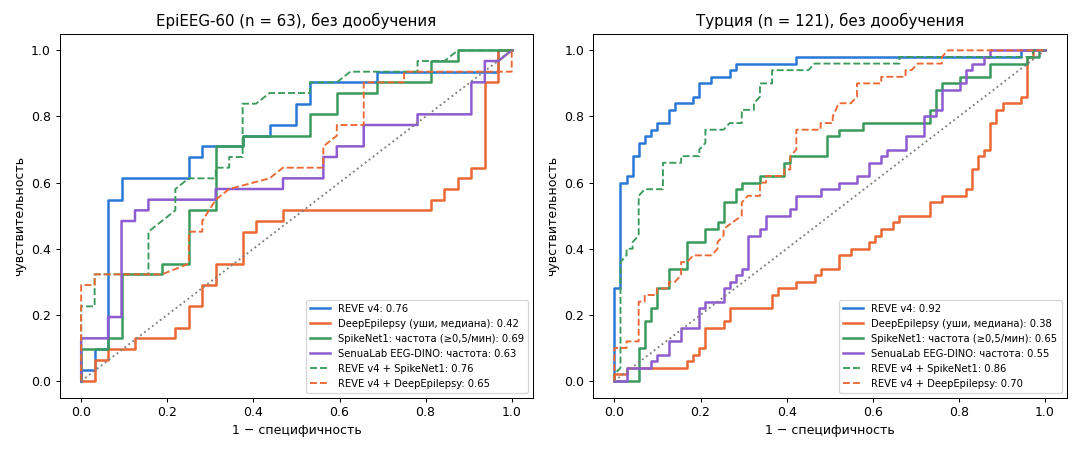

In [ ]:
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
SHOW = [("REVE v4", "#2a78d6", "-"), ("DeepEpilepsy (уши, медиана)", "#eb6834", "-"), ("SpikeNet1: частота (≥0,5/мин)", "#3a9b5c", "-"),
        ("SenuaLab EEG-DINO: частота", "#8e5bd0", "-"), ("REVE v4 + SpikeNet1", "#3a9b5c", "--"), ("REVE v4 + DeepEpilepsy", "#eb6834", "--")]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (ds, name) in zip(ax, [("epieeg60", "EpiEEG-60"), ("turkey", "Турция")]):
    d = D[D.dataset == ds]
    for m, col, ls in SHOW:
        if d[SC[m]].isna().any(): continue
        f, t, _ = roc_curve(d.y, d[SC[m]]); a.plot(f, t, color=col, ls=ls, lw=2 if ls == "-" else 1.5, label=f"{m}: {roc_auc_score(d.y, d[SC[m]]):.2f}")
    a.plot([0, 1], [0, 1], ":", color="gray"); a.set(xlabel="1 − специфичность", ylabel="чувствительность", title=f"{name} (n = {len(d)}), без дообучения"); a.legend(fontsize=8, loc="lower right")
plt.tight_layout(); os.makedirs(FIG, exist_ok=True); fig.savefig(f"{FIG}/epimodels_roc.png", dpi=90); plt.close(fig)
print("сохранено:", f"{FIG}/epimodels_roc.png", os.path.getsize(f"{FIG}/epimodels_roc.png") // 1000, "КБ")